## 0. Setup and configuration

In [ ]:
import os, re, io, sys, glob, json, time, random, shutil, tarfile, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); keras.utils.set_random_seed(seed)
set_seed()

OUT_DIR = "exp6_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def save_fig(name):
    """Save the CURRENT matplotlib figure (which may contain several subplots) as ONE PNG."""
    path = os.path.join(OUT_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("saved ->", path)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# ------------------- Configuration (assignment defaults) -------------------
N_SUBSET     = 3000   # balanced windows drawn from the UCI training partition (None = pool ALL 10,299 windows)
UNITS        = 32     # recurrent units
DROPOUT      = 0.2
DENSE_UNITS  = 16
LR           = 1e-3
BATCH        = 32
EPOCHS       = 30
SEQ_LENGTHS  = [32, 64, 128]

RESULTS = {"config": dict(N_SUBSET=N_SUBSET, UNITS=UNITS, DROPOUT=DROPOUT, DENSE_UNITS=DENSE_UNITS,
                          LR=LR, BATCH=BATCH, EPOCHS=EPOCHS, SEED=SEED, SEQ_LENGTHS=SEQ_LENGTHS,
                          tensorflow=tf.__version__)}

TensorFlow: 2.20.0 | Keras: 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load the UCI HAR raw inertial signals

The nine raw channels are: `body_acc_{x,y,z}`, `body_gyro_{x,y,z}`, `total_acc_{x,y,z}`.
Each window has 128 time steps, so one sample is `128 × 9`.

In [ ]:
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_DIR = "har_data"

def find_har_root():
    candidates = []
    for root, dirs, files in os.walk(HAR_DIR):
        if "__MACOSX" in root.split(os.sep):
            continue                                   # skip macOS zip resource-fork copies
        if "Inertial Signals" in dirs and os.path.basename(root) in ("train", "test"):
            sig_dir = os.path.join(root, "Inertial Signals")
            sig_files = [f for f in os.listdir(sig_dir) if f.endswith(".txt") and not f.startswith("._")]
            if len(sig_files) >= 9:                     # real data: 9 signal files, not AppleDouble stubs
                candidates.append(os.path.dirname(root))
    if not candidates:
        return None
    # prefer the shallowest valid path (closest to HAR_DIR root)
    candidates.sort(key=lambda p: p.count(os.sep))
    return candidates[0]

def prepare_har():
    root = find_har_root()
    if root:
        return root
    os.makedirs(HAR_DIR, exist_ok=True)
    zpath = os.path.join(HAR_DIR, "har.zip")
    if not os.path.exists(zpath):
        print("Downloading UCI HAR dataset ...")
        req = urllib.request.Request(HAR_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as r, open(zpath, "wb") as f:
            shutil.copyfileobj(r, f)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(HAR_DIR)
    # the UCI archive contains a nested "UCI HAR Dataset.zip"
    for _ in range(2):
        if find_har_root():
            break
        for p in glob.glob(os.path.join(HAR_DIR, "**", "*.zip"), recursive=True):
            if os.path.abspath(p) == os.path.abspath(zpath) or "__MACOSX" in p:
                continue
            with zipfile.ZipFile(p) as z:
                z.extractall(os.path.dirname(p))
    root = find_har_root()
    if root is None:
        raise RuntimeError("Could not locate 'Inertial Signals'. Download the dataset manually from "
                           "https://archive.ics.uci.edu/dataset/240 and unzip it into ./har_data/")
    return root

HAR_ROOT = prepare_har()
print("HAR root:", HAR_ROOT)

SIGNALS = ["body_acc_x", "body_acc_y", "body_acc_z",
           "body_gyro_x", "body_gyro_y", "body_gyro_z",
           "total_acc_x", "total_acc_y", "total_acc_z"]
ACTIVITIES = ["WALKING", "WALKING UPSTAIRS", "WALKING DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

def load_split(root, split):
    chans = []
    for s in SIGNALS:
        p = os.path.join(root, split, "Inertial Signals", f"{s}_{split}.txt")
        chans.append(pd.read_csv(p, sep=r"\s+", header=None).values)
    X = np.stack(chans, axis=-1).astype(np.float32)                      # (N, 128, 9)
    y = pd.read_csv(os.path.join(root, split, f"y_{split}.txt"), header=None).values.ravel().astype(int) - 1
    return X, y

Xtr0, ytr0 = load_split(HAR_ROOT, "train")
Xte0, yte0 = load_split(HAR_ROOT, "test")
print("Original UCI training partition :", Xtr0.shape, "| labels:", ytr0.shape)
print("Original UCI test partition     :", Xte0.shape, "| labels:", yte0.shape)
RESULTS["har_original"] = {"train_shape": list(Xtr0.shape), "test_shape": list(Xte0.shape)}

HAR root: har_data/UCI HAR Dataset
Original UCI training partition : (7352, 128, 9) | labels: (7352,)
Original UCI test partition     : (2947, 128, 9) | labels: (2947,)


## 2. Preprocessing

* Balanced subset (equal windows per class) from the UCI training partition (or all windows if `N_SUBSET=None`).
* Stratified **70 / 15 / 15** train / validation / test split.
* Per-channel z-score normalisation using **training-set statistics only**.

In [ ]:
if N_SUBSET is None:
    X_all = np.concatenate([Xtr0, Xte0]); y_all = np.concatenate([ytr0, yte0])
else:
    rng = np.random.RandomState(SEED)
    per_class = N_SUBSET // 6
    idx = []
    for c in range(6):
        cand = np.where(ytr0 == c)[0]
        idx.append(rng.choice(cand, size=min(per_class, len(cand)), replace=False))
    idx = np.concatenate(idx); rng.shuffle(idx)
    X_all, y_all = Xtr0[idx], ytr0[idx]

X_tr_raw, X_tmp, y_tr, y_tmp = train_test_split(X_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
X_va_raw, X_te_raw, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

def normalize_splits(tr, va, te):
    """z-score per channel with statistics computed on the training split only."""
    mu = tr.mean(axis=(0, 1), keepdims=True)
    sd = tr.std(axis=(0, 1), keepdims=True) + 1e-8
    return [((a - mu) / sd).astype(np.float32) for a in (tr, va, te)]

X_tr, X_va, X_te = normalize_splits(X_tr_raw, X_va_raw, X_te_raw)

print("Input tensor shape:")
print("Training   :", X_tr.shape)
print("Validation :", X_va.shape)
print("Testing    :", X_te.shape)
print("Number of classes            :", len(ACTIVITIES))
print("Number of features per step  :", X_tr.shape[2])
print("Sequence length              :", X_tr.shape[1])

dist = pd.DataFrame({
    "Class": ACTIVITIES,
    "Train": np.bincount(y_tr, minlength=6),
    "Validation": np.bincount(y_va, minlength=6),
    "Test": np.bincount(y_te, minlength=6)})
dist.loc[len(dist)] = ["TOTAL", len(y_tr), len(y_va), len(y_te)]
print("\nClass distribution:")
print(dist.to_string(index=False))
print("\nTrain-channel mean after normalisation (should be ~0):", np.round(X_tr.mean(axis=(0, 1)), 3))
print("Train-channel std  after normalisation (should be ~1):", np.round(X_tr.std(axis=(0, 1)), 3))

RESULTS["preprocessing"] = {
    "train_shape": list(X_tr.shape), "val_shape": list(X_va.shape), "test_shape": list(X_te.shape),
    "n_classes": 6, "n_features": int(X_tr.shape[2]), "seq_len": int(X_tr.shape[1]),
    "class_counts": {"train": np.bincount(y_tr, minlength=6).tolist(),
                     "val": np.bincount(y_va, minlength=6).tolist(),
                     "test": np.bincount(y_te, minlength=6).tolist()},
    "classes": ACTIVITIES}

Input tensor shape:
Training   : (2100, 128, 9)
Validation : (450, 128, 9)
Testing    : (450, 128, 9)
Number of classes            : 6
Number of features per step  : 9
Sequence length              : 128

Class distribution:
             Class  Train  Validation  Test
           WALKING    350          75    75
  WALKING UPSTAIRS    350          75    75
WALKING DOWNSTAIRS    350          75    75
           SITTING    350          75    75
          STANDING    350          75    75
            LAYING    350          75    75
             TOTAL   2100         450   450

Train-channel mean after normalisation (should be ~0): [ 0.  0. -0. -0. -0.  0.  0. -0. -0.]
Train-channel std  after normalisation (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 3. Plot 1 — Temporal sensor signals
One representative window per activity; three channels; dynamic activities (top row) vs. static activities (bottom row). All six panels are drawn on a single combined figure.

saved -> exp6_outputs/plot1_temporal_sensor_signals.png


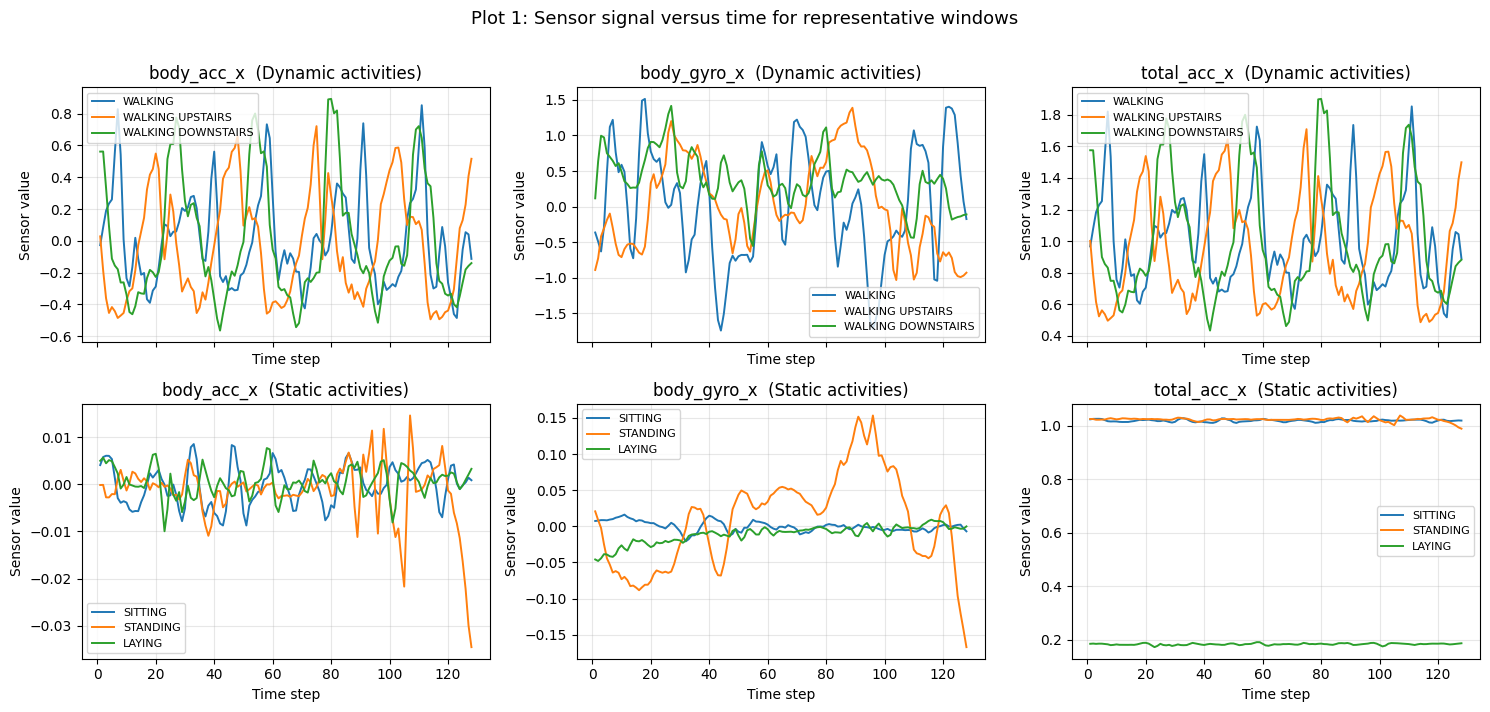

Per-activity summary of the plotted windows (std of each plotted channel over the 128 steps):
          Activity  body_acc_x std  body_gyro_x std  total_acc_x std
           WALKING          0.2897           0.7701           0.2893
  WALKING UPSTAIRS          0.3352           0.6289           0.3353
WALKING DOWNSTAIRS          0.3816           0.3509           0.3806
           SITTING          0.0041           0.0069           0.0041
          STANDING          0.0066           0.0653           0.0067
            LAYING          0.0030           0.0120           0.0030


In [ ]:
rng_v = np.random.RandomState(SEED)
rep = {c: rng_v.choice(np.where(y_tr == c)[0]) for c in range(6)}      # one window per class (training set, raw units)
show_channels = [SIGNALS.index("body_acc_x"), SIGNALS.index("body_gyro_x"), SIGNALS.index("total_acc_x")]
t_axis = np.arange(1, 129)
groups = [("Dynamic activities", [0, 1, 2]), ("Static activities", [3, 4, 5])]

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for r, (gname, cls_list) in enumerate(groups):
    for ccol, ch in enumerate(show_channels):
        ax = axes[r, ccol]
        for c in cls_list:
            ax.plot(t_axis, X_tr_raw[rep[c], :, ch], label=ACTIVITIES[c], lw=1.4)
        ax.set_title(f"{SIGNALS[ch]}  ({gname})")
        ax.set_xlabel("Time step"); ax.set_ylabel("Sensor value"); ax.legend(fontsize=8)
plt.suptitle("Plot 1: Sensor signal versus time for representative windows", y=1.01, fontsize=13)
plt.tight_layout(); save_fig("plot1_temporal_sensor_signals.png"); plt.show()

print("Per-activity summary of the plotted windows (std of each plotted channel over the 128 steps):")
rows = []
for c in range(6):
    rows.append([ACTIVITIES[c]] + [round(float(X_tr_raw[rep[c], :, ch].std()), 4) for ch in show_channels])
print(pd.DataFrame(rows, columns=["Activity"] + [SIGNALS[i] + " std" for i in show_channels]).to_string(index=False))

## 4. Numerical RNN exercise
$x_1=0.5,\ x_2=0.7,\ x_3=0.2,\ h_0=0,\ W_x=0.5,\ W_h=0.8,\ b=0.1$, with $h_t=\tanh(W_x x_t + W_h h_{t-1} + b)$.
The values below are computed by (a) a plain NumPy loop and (b) a Keras `SimpleRNN` whose weights are set to the same numbers. Compare them with your hand calculation.

In [ ]:
x_seq = [0.5, 0.7, 0.2]; Wx, Wh, b = 0.5, 0.8, 0.1
h = 0.0; rows = []; h_np = []
for t, xt in enumerate(x_seq, start=1):
    pre = Wx * xt + Wh * h + b
    h_new = float(np.tanh(pre))
    rows.append([f"h{t}", f"{Wx}*{xt} + {Wh}*{h:.6f} + {b}", pre, h_new])
    h_np.append(h_new); h = h_new
print(pd.DataFrame(rows, columns=["state", "pre-activation expression", "pre-activation", "h_t = tanh(.)"]).to_string(index=False))

inp = layers.Input((3, 1))
rnn_layer = layers.SimpleRNN(1, activation="tanh", return_sequences=True)
m_num = keras.Model(inp, rnn_layer(inp))
rnn_layer.set_weights([np.array([[Wx]], dtype="float32"), np.array([[Wh]], dtype="float32"), np.array([b], dtype="float32")])
h_keras = m_num.predict(np.array(x_seq, dtype="float32").reshape(1, 3, 1), verbose=0).ravel()
print("\nNumPy  h1,h2,h3 :", np.round(h_np, 6))
print("Keras  h1,h2,h3 :", np.round(h_keras, 6))
print("Max absolute difference:", float(np.max(np.abs(np.array(h_np) - h_keras))))
RESULTS["numerical_exercise"] = {"numpy_h": h_np, "keras_h": h_keras.tolist(),
                                 "max_abs_diff": float(np.max(np.abs(np.array(h_np) - h_keras)))}

state    pre-activation expression  pre-activation  h_t = tanh(.)
   h1 0.5*0.5 + 0.8*0.000000 + 0.1        0.350000       0.336376
   h2 0.5*0.7 + 0.8*0.336376 + 0.1        0.719100       0.616352
   h3 0.5*0.2 + 0.8*0.616352 + 0.1        0.693081       0.599958

NumPy  h1,h2,h3 : [0.336376 0.616352 0.599958]
Keras  h1,h2,h3 : [0.336376 0.616352 0.599958]
Max absolute difference: 5.907954325756748e-08


## 5. Model definitions (RNN / LSTM / GRU)

All three classifiers share **exactly** the same input, dropout, dense head, optimizer, batch size, epochs, loss and seed. Only the recurrent layer is replaced.

`Input(T×9) → {SimpleRNN | LSTM | GRU}(32) → Dropout(0.2) → Dense(16, ReLU) → Dense(6, Softmax)`

In [ ]:
REC = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}
KINDS = ["RNN", "LSTM", "GRU"]

def build_recurrent_classifier(kind, T, F=9, n_classes=6, units=UNITS):
    inp = layers.Input((T, F), name="input")
    x = REC[kind](units, name=f"{kind.lower()}_layer")(inp)
    x = layers.Dropout(DROPOUT)(x)
    x = layers.Dense(DENSE_UNITS, activation="relu")(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inp, out, name=f"{kind}_classifier")
    model.compile(optimizer=keras.optimizers.Adam(LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def n_trainable(m):
    return int(sum(int(np.prod(list(w.shape))) for w in m.trainable_weights))

class EveryN(keras.callbacks.Callback):
    def __init__(self, n=5): super().__init__(); self.n = n
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.n == 0 or epoch == 0 or (epoch + 1) == self.params.get("epochs"):
            print(f"  epoch {epoch+1:3d} | loss {logs['loss']:.4f} acc {logs['accuracy']:.4f} | "
                  f"val_loss {logs['val_loss']:.4f} val_acc {logs['val_accuracy']:.4f}")

def macro_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return float(np.mean(np.array(y_true) == np.array(y_pred)) * 100), float(p * 100), float(r * 100), float(f * 100)

def train_and_eval(kind, Xtr, ytr, Xva, yva, Xte, yte, epochs=EPOCHS, log_every=5):
    set_seed()                                     # identical seed for every model
    model = build_recurrent_classifier(kind, Xtr.shape[1], Xtr.shape[2])
    t0 = time.time()
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=BATCH,
                     verbose=0, callbacks=[EveryN(log_every)])
    train_time = time.time() - t0
    prob = model.predict(Xte, batch_size=256, verbose=0)
    pred = prob.argmax(1)
    acc, p, r, f = macro_metrics(yte, pred)
    return dict(model=model, history=hist.history, train_time=train_time, params=n_trainable(model),
                acc=acc, precision=p, recall=r, f1=f, pred=pred,
                cm=confusion_matrix(yte, pred, labels=list(range(6))), epochs=epochs)

# ---- GPU warm-up so that the first timed model is not penalised by CUDA/cuDNN initialisation ----
for k in KINDS:
    set_seed(); wm = build_recurrent_classifier(k, 128, 9)
    wm.fit(X_tr[:256], y_tr[:256], epochs=1, batch_size=BATCH, verbose=0)
    del wm
print("Warm-up done.")

# ---- Analytical parameter counts (as a sanity check against Keras) ----
F_, u, D1, C = 9, UNITS, DENSE_UNITS, 6
head = (u * D1 + D1) + (D1 * C + C)
analytic = {"RNN": u * (F_ + u + 1) + head,
            "LSTM": 4 * u * (F_ + u + 1) + head,
            "GRU": 3 * u * (F_ + u + 2) + head}      # Keras GRU default: reset_after=True (two bias vectors)
print("Analytical trainable-parameter counts:", analytic)

Warm-up done.
Analytical trainable-parameter counts: {'RNN': 1974, 'LSTM': 6006, 'GRU': 4758}


## 6. Train RNN, LSTM and GRU on the full sequence length (T = 128)

In [ ]:
R = {}
for kind in KINDS:
    print(f"\n=== Training {kind} ===")
    R[kind] = train_and_eval(kind, X_tr, y_tr, X_va, y_va, X_te, y_te)
    print(f"{kind}: trainable params = {R[kind]['params']:,} | training time = {R[kind]['train_time']:.2f} s | "
          f"TEST acc = {R[kind]['acc']:.2f}% | macro-F1 = {R[kind]['f1']:.2f}%")

for kind in KINDS:
    print(f"\n----- {kind} model summary -----")
    R[kind]["model"].summary()


=== Training RNN ===
  epoch   1 | loss 1.6512 acc 0.3600 | val_loss 1.5340 val_acc 0.4156
  epoch   5 | loss 1.0603 acc 0.5719 | val_loss 0.9344 val_acc 0.5889
  epoch  10 | loss 0.7090 acc 0.6724 | val_loss 0.6963 val_acc 0.6756
  epoch  15 | loss 0.6149 acc 0.7148 | val_loss 0.6265 val_acc 0.7222
  epoch  20 | loss 0.5549 acc 0.7538 | val_loss 0.5492 val_acc 0.7711
  epoch  25 | loss 0.6612 acc 0.7333 | val_loss 0.5977 val_acc 0.7556
  epoch  30 | loss 0.5149 acc 0.7895 | val_loss 0.5156 val_acc 0.7956
RNN: trainable params = 1,974 | training time = 27.94 s | TEST acc = 77.33% | macro-F1 = 76.93%

=== Training LSTM ===
  epoch   1 | loss 1.6100 acc 0.3657 | val_loss 1.3982 val_acc 0.3733
  epoch   5 | loss 0.6620 acc 0.7429 | val_loss 0.6369 val_acc 0.7533
  epoch  10 | loss 0.2371 acc 0.9210 | val_loss 0.3027 val_acc 0.9000
  epoch  15 | loss 0.1804 acc 0.9367 | val_loss 0.1941 val_acc 0.9356
  epoch  20 | loss 0.1232 acc 0.9543 | val_loss 0.1498 val_acc 0.9311
  epoch  25 | loss 

LSTM: trainable params = 6,006 | training time = 24.49 s | TEST acc = 94.44% | macro-F1 = 94.41%

=== Training GRU ===
  epoch   1 | loss 1.6199 acc 0.3233 | val_loss 1.4408 val_acc 0.4689
  epoch   5 | loss 0.5890 acc 0.7586 | val_loss 0.4906 val_acc 0.7778
  epoch  10 | loss 0.1911 acc 0.9410 | val_loss 0.1445 val_acc 0.9400
  epoch  15 | loss 0.1285 acc 0.9552 | val_loss 0.1158 val_acc 0.9356
  epoch  20 | loss 0.1270 acc 0.9529 | val_loss 0.1171 val_acc 0.9467
  epoch  25 | loss 0.1115 acc 0.9595 | val_loss 0.1167 val_acc 0.9422


  epoch  30 | loss 0.1064 acc 0.9557 | val_loss 0.1176 val_acc 0.9400
GRU: trainable params = 4,758 | training time = 25.71 s | TEST acc = 94.67% | macro-F1 = 94.66%

----- RNN model summary -----


Model: "RNN_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 128, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rnn_layer (SimpleRNN)           │ (None, 32)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,924 (23.14 KB)

... (13 outputs left out)

 Total params: 14,276 (55.77 KB)

 Trainable params: 4,758 (18.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,518 (37.18 KB)

## 7. Plots 2 and 3 — Training / validation loss and accuracy
For each model this produces **one combined figure**: a 1×2 grid with the loss curves on the left (Plot 2) and the accuracy curves on the right (Plot 3), saved as a single PNG per model. A further combined figure stacks all three models' loss+accuracy rows into one grid image.

saved -> exp6_outputs/plot23_rnn_loss_accuracy.png


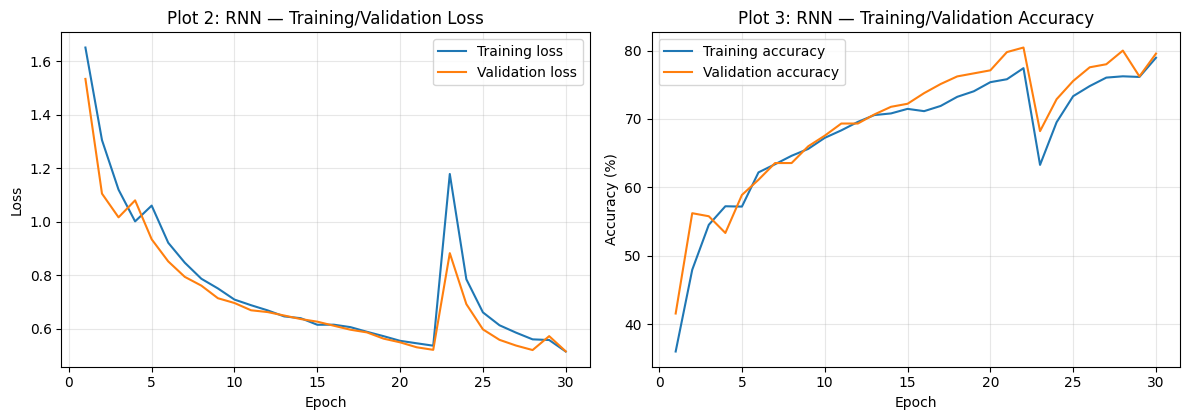

[RNN] final train loss 0.5149 | final val loss 0.5156 | min val loss 0.5156 @ epoch 30
[RNN] final train acc 78.95% | final val acc 79.56% | best val acc 80.44% @ epoch 22 | gap (train-val) -0.60 pts
[RNN] first epoch with val acc >= 80%: 22 | >= 90%: None | val-loss (last 5 epochs) mean 0.5408, std 0.0218

saved -> exp6_outputs/plot23_lstm_loss_accuracy.png


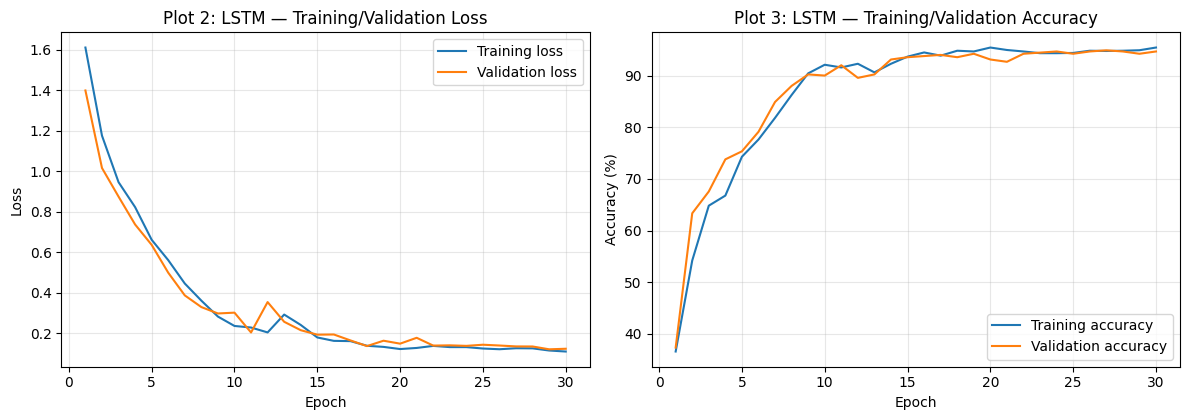

[LSTM] final train loss 0.1110 | final val loss 0.1247 | min val loss 0.1220 @ epoch 29
[LSTM] final train acc 95.43% | final val acc 94.67% | best val acc 94.89% @ epoch 27 | gap (train-val) 0.76 pts
[LSTM] first epoch with val acc >= 80%: 7 | >= 90%: 9 | val-loss (last 5 epochs) mean 0.1319, std 0.0072

saved -> exp6_outputs/plot23_gru_loss_accuracy.png


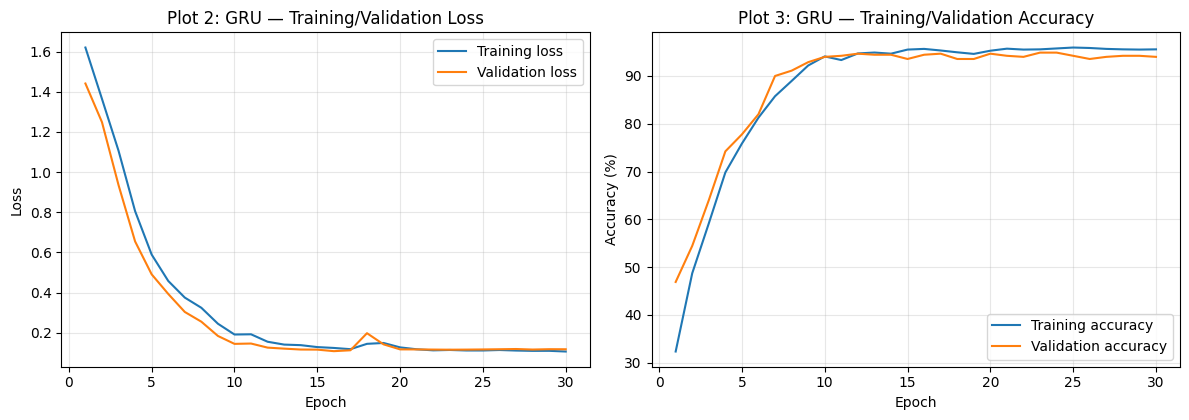

[GRU] final train loss 0.1064 | final val loss 0.1176 | min val loss 0.1081 @ epoch 16
[GRU] final train acc 95.57% | final val acc 94.00% | best val acc 94.89% @ epoch 23 | gap (train-val) 1.57 pts
[GRU] first epoch with val acc >= 80%: 6 | >= 90%: 8 | val-loss (last 5 epochs) mean 0.1177, std 0.0008

saved -> exp6_outputs/plot23_all_models_loss_accuracy_grid.png


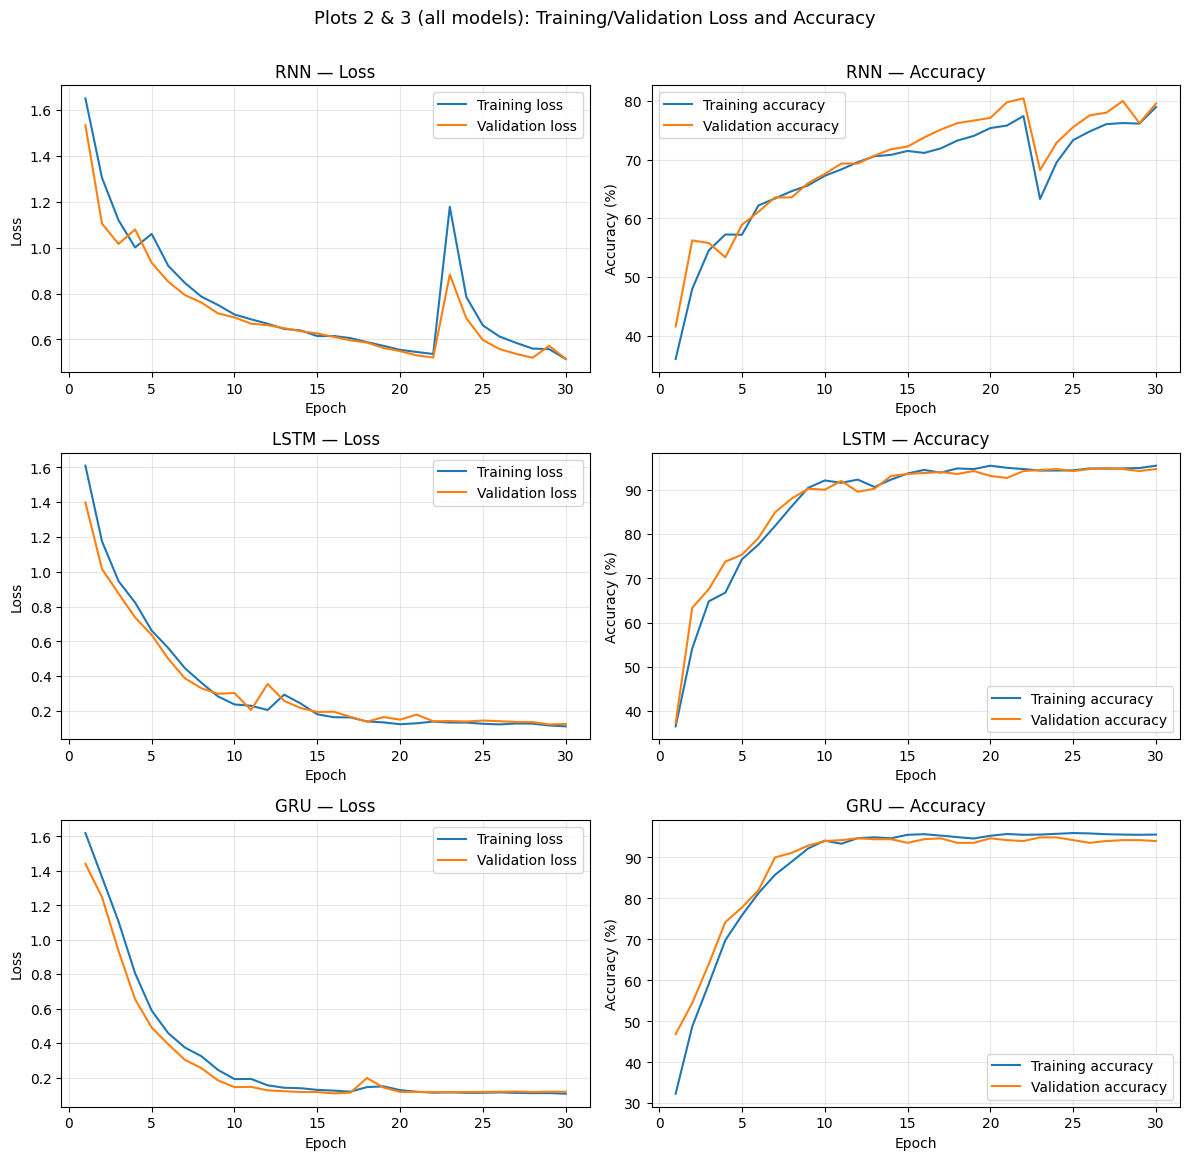

In [ ]:
def plot_curves_combined(h, title, fname, p_loss="Plot 2", p_acc="Plot 3"):
    """One figure, two subplots side-by-side (loss | accuracy) -> saved as ONE PNG."""
    ep = np.arange(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    axes[0].plot(ep, h["loss"], label="Training loss"); axes[0].plot(ep, h["val_loss"], label="Validation loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title(f"{p_loss}: {title} — Training/Validation Loss"); axes[0].legend()
    axes[1].plot(ep, np.array(h["accuracy"]) * 100, label="Training accuracy")
    axes[1].plot(ep, np.array(h["val_accuracy"]) * 100, label="Validation accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].set_title(f"{p_acc}: {title} — Training/Validation Accuracy"); axes[1].legend()
    plt.tight_layout(); save_fig(fname); plt.show()

def diagnostics(name, h):
    tl, vl = np.array(h["loss"]), np.array(h["val_loss"])
    ta, va = np.array(h["accuracy"]) * 100, np.array(h["val_accuracy"]) * 100
    first = lambda thr: (int(np.argmax(va >= thr)) + 1) if (va >= thr).any() else None
    d = dict(final_train_loss=float(tl[-1]), final_val_loss=float(vl[-1]),
             min_val_loss=float(vl.min()), min_val_loss_epoch=int(vl.argmin()) + 1,
             final_train_acc=float(ta[-1]), final_val_acc=float(va[-1]),
             best_val_acc=float(va.max()), best_val_acc_epoch=int(va.argmax()) + 1,
             final_gap_pts=float(ta[-1] - va[-1]),
             first_epoch_val_acc_ge_80=first(80), first_epoch_val_acc_ge_90=first(90),
             val_loss_last5_mean=float(vl[-5:].mean()), val_loss_last5_std=float(vl[-5:].std()))
    print(f"[{name}] final train loss {d['final_train_loss']:.4f} | final val loss {d['final_val_loss']:.4f} | "
          f"min val loss {d['min_val_loss']:.4f} @ epoch {d['min_val_loss_epoch']}")
    print(f"[{name}] final train acc {d['final_train_acc']:.2f}% | final val acc {d['final_val_acc']:.2f}% | "
          f"best val acc {d['best_val_acc']:.2f}% @ epoch {d['best_val_acc_epoch']} | gap (train-val) {d['final_gap_pts']:.2f} pts")
    print(f"[{name}] first epoch with val acc >= 80%: {d['first_epoch_val_acc_ge_80']} | >= 90%: {d['first_epoch_val_acc_ge_90']} | "
          f"val-loss (last 5 epochs) mean {d['val_loss_last5_mean']:.4f}, std {d['val_loss_last5_std']:.4f}")
    return d

RESULTS["training_diagnostics"] = {}
for kind in KINDS:
    plot_curves_combined(R[kind]["history"], kind, f"plot23_{kind.lower()}_loss_accuracy.png")
    RESULTS["training_diagnostics"][kind] = diagnostics(kind, R[kind]["history"])
    print()

# ---- one grid image stacking RNN / LSTM / GRU (loss | accuracy) for a single-glance comparison ----
fig, axes = plt.subplots(3, 2, figsize=(12, 11.5))
for i, kind in enumerate(KINDS):
    h = R[kind]["history"]; ep = np.arange(1, len(h["loss"]) + 1)
    axes[i, 0].plot(ep, h["loss"], label="Training loss"); axes[i, 0].plot(ep, h["val_loss"], label="Validation loss")
    axes[i, 0].set_title(f"{kind} — Loss"); axes[i, 0].set_xlabel("Epoch"); axes[i, 0].set_ylabel("Loss"); axes[i, 0].legend()
    axes[i, 1].plot(ep, np.array(h["accuracy"]) * 100, label="Training accuracy")
    axes[i, 1].plot(ep, np.array(h["val_accuracy"]) * 100, label="Validation accuracy")
    axes[i, 1].set_title(f"{kind} — Accuracy"); axes[i, 1].set_xlabel("Epoch"); axes[i, 1].set_ylabel("Accuracy (%)"); axes[i, 1].legend()
plt.suptitle("Plots 2 & 3 (all models): Training/Validation Loss and Accuracy", y=1.005, fontsize=13)
plt.tight_layout(); save_fig("plot23_all_models_loss_accuracy_grid.png"); plt.show()

## 8. Test-set evaluation and Plot 4 — Confusion matrices
All three models' confusion matrices are drawn as three panels of a single combined figure.

===== RNN : TEST-SET RESULTS =====
                    precision    recall  f1-score   support

           WALKING     0.5536    0.4133    0.4733        75
  WALKING UPSTAIRS     0.5761    0.7067    0.6347        75
WALKING DOWNSTAIRS     0.8889    0.8533    0.8707        75
           SITTING     0.8750    0.7467    0.8058        75
          STANDING     0.7582    0.9200    0.8313        75
            LAYING     1.0000    1.0000    1.0000        75

          accuracy                         0.7733       450
         macro avg     0.7753    0.7733    0.7693       450
      weighted avg     0.7753    0.7733    0.7693       450

--- RNN: per-class recall (%) and misclassification counts ---
             Class  Support  Correct  Errors  Recall %
           WALKING       75       31      44     41.33
  WALKING UPSTAIRS       75       53      22     70.67
WALKING DOWNSTAIRS       75       64      11     85.33
           SITTING       75       56      19     74.67
          STANDING      

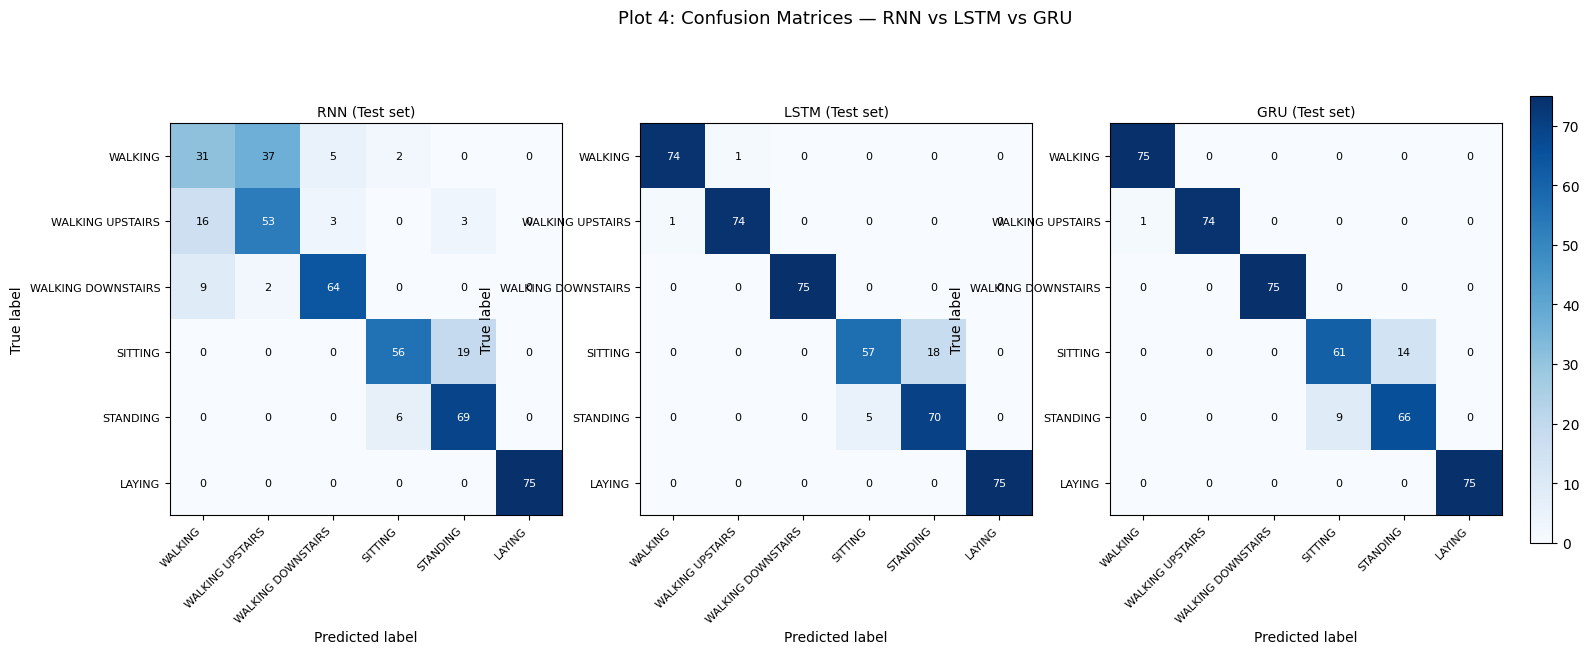

Total misclassified test windows per model: {'RNN': 102, 'LSTM': 25, 'GRU': 24} of 450


In [ ]:
def plot_confusion_ax(ax, cm, labels, title):
    im = ax.imshow(cm, cmap="Blues"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(labels, fontsize=8)
    thr = cm.max() / 2.0 if cm.max() > 0 else 0.5
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > thr else "black", fontsize=8)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(title, fontsize=10)
    return im

def confusion_report(name, cm, labels, k=5):
    support = cm.sum(axis=1)
    recall = np.divide(np.diag(cm), support, out=np.zeros(len(labels)), where=support > 0) * 100
    errors = support - np.diag(cm)
    pairs = [(int(cm[i, j]), labels[i], labels[j]) for i in range(len(labels)) for j in range(len(labels)) if i != j and cm[i, j] > 0]
    pairs.sort(reverse=True)
    print(f"--- {name}: per-class recall (%) and misclassification counts ---")
    print(pd.DataFrame({"Class": labels, "Support": support, "Correct": np.diag(cm), "Errors": errors,
                        "Recall %": np.round(recall, 2)}).to_string(index=False))
    print(f"Highest recall : {labels[int(recall.argmax())]} ({recall.max():.2f}%)")
    print(f"Lowest recall  : {labels[int(recall.argmin())]} ({recall.min():.2f}%)")
    print(f"Most errors    : {labels[int(errors.argmax())]} ({int(errors.max())} misclassified windows)")
    print("Most frequent confusions (count, true -> predicted):")
    for cnt, a, b_ in pairs[:k]:
        print(f"   {cnt:3d}  {a}  ->  {b_}")
    print()
    return dict(recall_pct=recall.tolist(), errors=errors.tolist(), top_confusions=[[c, a, b_] for c, a, b_ in pairs[:k]])

RESULTS["models"] = {}
RESULTS["confusion_analysis"] = {}
for kind in KINDS:
    r = R[kind]
    print(f"===== {kind} : TEST-SET RESULTS =====")
    print(classification_report(y_te, r["pred"], target_names=ACTIVITIES, digits=4, zero_division=0))
    RESULTS["confusion_analysis"][kind] = confusion_report(kind, r["cm"], ACTIVITIES)
    RESULTS["models"][kind] = dict(accuracy=r["acc"], macro_precision=r["precision"], macro_recall=r["recall"],
                                   macro_f1=r["f1"], params=r["params"], train_time_s=r["train_time"],
                                   epochs=r["epochs"], confusion_matrix=r["cm"].tolist())

# ---- Plot 4: all three confusion matrices as ONE combined figure ----
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))
ims = []
for ax, kind in zip(axes, KINDS):
    ims.append(plot_confusion_ax(ax, R[kind]["cm"], ACTIVITIES, f"{kind} (Test set)"))
plt.suptitle("Plot 4: Confusion Matrices — RNN vs LSTM vs GRU", y=1.03, fontsize=13)
fig.colorbar(ims[-1], ax=axes, fraction=0.025, pad=0.02)
save_fig("plot4_confusion_all_models.png"); plt.show()

# Are the errors consistent across models?
print("Total misclassified test windows per model:",
      {k: int(R[k]["cm"].sum() - np.trace(R[k]["cm"])) for k in KINDS}, "of", len(y_te))

## 9. Metrics table, RNN vs LSTM vs GRU comparison and Plot 5

Test-set performance (independent 15% test split):
             Metric     RNN    LSTM     GRU
       Accuracy (%)   77.33   94.44   94.67
Macro Precision (%)   77.53   94.80   94.72
   Macro Recall (%)   77.33   94.44   94.67
       Macro F1 (%)   76.93   94.41   94.66
         Parameters 1974.00 6006.00 4758.00
  Training Time (s)   27.94   24.49   25.71

Keras parameter count vs analytical formula:
Model  Keras trainable  Analytical
  RNN             1974        1974
 LSTM             6006        6006
  GRU             4758        4758
saved -> exp6_outputs/plot5_model_performance_comparison.png


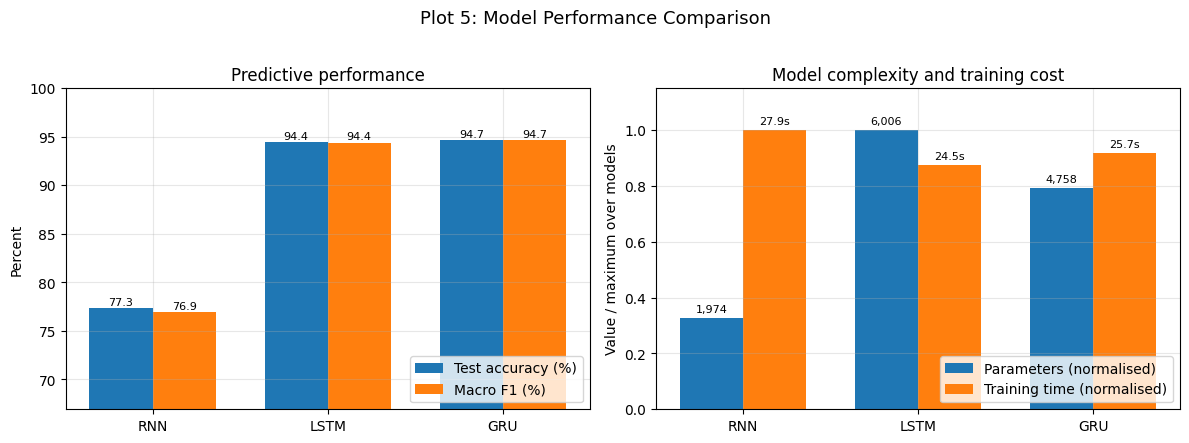


          Property   RNN  LSTM   GRU
     Hidden state   Yes   Yes   Yes
       Cell state    No   Yes    No
      Forget gate    No   Yes    No
       Input gate    No   Yes    No
      Output gate    No   Yes    No
      Update gate    No    No   Yes
       Reset gate    No    No   Yes
       Parameters 1,974 6,006 4,758
Training time (s) 27.94 24.49 25.71
      Test F1 (%) 76.93 94.41 94.66

Highest observed macro-F1: GRU (94.66%) | highest observed accuracy: GRU (94.67%)


In [ ]:
metrics_df = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Macro Precision (%)", "Macro Recall (%)", "Macro F1 (%)", "Parameters", "Training Time (s)"],
    **{k: [R[k]["acc"], R[k]["precision"], R[k]["recall"], R[k]["f1"], R[k]["params"], R[k]["train_time"]] for k in KINDS}})
print("Test-set performance (independent 15% test split):")
print(metrics_df.round(2).to_string(index=False))

print("\nKeras parameter count vs analytical formula:")
print(pd.DataFrame({"Model": KINDS, "Keras trainable": [R[k]["params"] for k in KINDS],
                    "Analytical": [analytic[k] for k in KINDS]}).to_string(index=False))

# ---- Plot 5 (already a single combined figure with two subplots) ----
accs = np.array([R[k]["acc"] for k in KINDS]); f1s = np.array([R[k]["f1"] for k in KINDS])
pars = np.array([R[k]["params"] for k in KINDS], dtype=float); tms = np.array([R[k]["train_time"] for k in KINDS])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = np.arange(3); w = 0.36
b1 = axes[0].bar(x - w/2, accs, w, label="Test accuracy (%)"); b2 = axes[0].bar(x + w/2, f1s, w, label="Macro F1 (%)")
axes[0].set_xticks(x); axes[0].set_xticklabels(KINDS); axes[0].set_ylabel("Percent")
lo = max(0, min(accs.min(), f1s.min()) - 10); axes[0].set_ylim(lo, 100)
for bars in (b1, b2):
    for bar in bars:
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{bar.get_height():.1f}", ha="center", fontsize=8)
axes[0].set_title("Predictive performance"); axes[0].legend(loc="lower right")
b3 = axes[1].bar(x - w/2, pars / pars.max(), w, label="Parameters (normalised)"); b4 = axes[1].bar(x + w/2, tms / tms.max(), w, label="Training time (normalised)")
axes[1].set_xticks(x); axes[1].set_xticklabels(KINDS); axes[1].set_ylabel("Value / maximum over models"); axes[1].set_ylim(0, 1.15)
for bars, vals, fmt in ((b3, pars, "{:,.0f}"), (b4, tms, "{:.1f}s")):
    for bar, v in zip(bars, vals):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, fmt.format(v), ha="center", fontsize=8)
axes[1].set_title("Model complexity and training cost"); axes[1].legend(loc="lower right")
plt.suptitle("Plot 5: Model Performance Comparison", y=1.02, fontsize=13)
plt.tight_layout(); save_fig("plot5_model_performance_comparison.png"); plt.show()

# ---- Structural comparison table required by the assignment ----
struct = pd.DataFrame({
    "Property": ["Hidden state", "Cell state", "Forget gate", "Input gate", "Output gate", "Update gate", "Reset gate",
                 "Parameters", "Training time (s)", "Test F1 (%)"],
    "RNN":  ["Yes", "No", "No", "No", "No", "No", "No", f"{R['RNN']['params']:,}",  f"{R['RNN']['train_time']:.2f}",  f"{R['RNN']['f1']:.2f}"],
    "LSTM": ["Yes", "Yes", "Yes", "Yes", "Yes", "No", "No", f"{R['LSTM']['params']:,}", f"{R['LSTM']['train_time']:.2f}", f"{R['LSTM']['f1']:.2f}"],
    "GRU":  ["Yes", "No", "No", "No", "No", "Yes", "Yes", f"{R['GRU']['params']:,}",  f"{R['GRU']['train_time']:.2f}",  f"{R['GRU']['f1']:.2f}"]})
print("\n", struct.to_string(index=False))
best_f1 = max(KINDS, key=lambda k: R[k]["f1"]); best_acc = max(KINDS, key=lambda k: R[k]["acc"])
print(f"\nHighest observed macro-F1: {best_f1} ({R[best_f1]['f1']:.2f}%) | highest observed accuracy: {best_acc} ({R[best_acc]['acc']:.2f}%)")

## 10. Effect of sequence length — T ∈ {32, 64, 128} (Plot 6)

For a shorter length $T$ the **first $T$ time steps** of every window are kept (consistent truncation for train/val/test), the channels are re-normalised with training statistics of the truncated data, and the three models are retrained with exactly the same settings. $T=128$ re-uses the main runs above.


=== T = 32 | RNN ===
  epoch   1 | loss 1.6081 acc 0.3776 | val_loss 1.3110 val_acc 0.5378
  epoch  10 | loss 0.6671 acc 0.6910 | val_loss 0.6790 val_acc 0.6822
  epoch  20 | loss 0.5194 acc 0.7905 | val_loss 0.5393 val_acc 0.7956
  epoch  30 | loss 0.4357 acc 0.8257 | val_loss 0.4642 val_acc 0.8178
  T=32 RNN: test acc 79.33% | macro-F1 79.18% | time 18.46s | params 1,974

=== T = 32 | LSTM ===
  epoch   1 | loss 1.6152 acc 0.3562 | val_loss 1.4128 val_acc 0.3711
  epoch  10 | loss 0.2251 acc 0.9167 | val_loss 0.2307 val_acc 0.9133
  epoch  20 | loss 0.1292 acc 0.9471 | val_loss 0.1617 val_acc 0.9289
  epoch  30 | loss 0.1417 acc 0.9424 | val_loss 0.1941 val_acc 0.9222
  T=32 LSTM: test acc 94.22% | macro-F1 94.20% | time 19.35s | params 6,006

=== T = 32 | GRU ===
  epoch   1 | loss 1.6234 acc 0.3062 | val_loss 1.4550 val_acc 0.4000
  epoch  10 | loss 0.3080 acc 0.8862 | val_loss 0.3132 val_acc 0.8756
  epoch  20 | loss 0.1508 acc 0.9390 | val_loss 0.1746 val_acc 0.9200
  epoch  30 

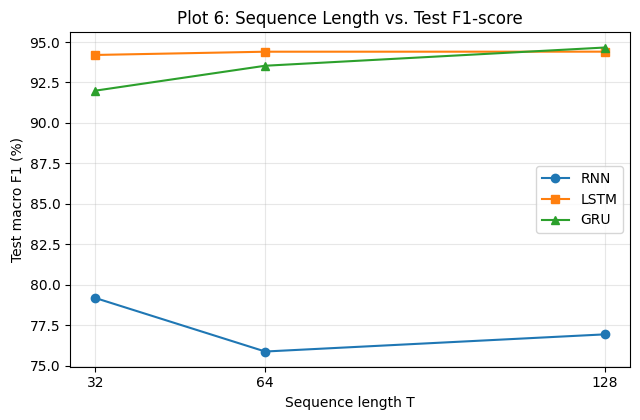

In [ ]:
SEQ = {}
for T in SEQ_LENGTHS:
    SEQ[T] = {}
    if T == 128:
        for k in KINDS:
            SEQ[T][k] = dict(f1=R[k]["f1"], acc=R[k]["acc"], time=R[k]["train_time"], params=R[k]["params"])
        continue
    a, b_, c_ = normalize_splits(X_tr_raw[:, :T, :], X_va_raw[:, :T, :], X_te_raw[:, :T, :])
    for k in KINDS:
        print(f"\n=== T = {T} | {k} ===")
        rr = train_and_eval(k, a, y_tr, b_, y_va, c_, y_te, log_every=10)
        SEQ[T][k] = dict(f1=rr["f1"], acc=rr["acc"], time=rr["train_time"], params=rr["params"])
        print(f"  T={T} {k}: test acc {rr['acc']:.2f}% | macro-F1 {rr['f1']:.2f}% | time {rr['train_time']:.2f}s | params {rr['params']:,}")
        del rr

f1_table = pd.DataFrame({"Sequence Length": SEQ_LENGTHS, **{f"{k} F1 (%)": [SEQ[T][k]["f1"] for T in SEQ_LENGTHS] for k in KINDS}})
acc_table = pd.DataFrame({"Sequence Length": SEQ_LENGTHS, **{f"{k} Acc (%)": [SEQ[T][k]["acc"] for T in SEQ_LENGTHS] for k in KINDS}})
time_table = pd.DataFrame({"Sequence Length": SEQ_LENGTHS, **{f"{k} time (s)": [SEQ[T][k]["time"] for T in SEQ_LENGTHS] for k in KINDS}})
print("\nTest macro-F1 vs sequence length:"); print(f1_table.round(2).to_string(index=False))
print("\nTest accuracy vs sequence length:"); print(acc_table.round(2).to_string(index=False))
print("\nTraining time vs sequence length:"); print(time_table.round(2).to_string(index=False))

plt.figure(figsize=(6.5, 4.3))
for k, mk in zip(KINDS, ["o", "s", "^"]):
    plt.plot(SEQ_LENGTHS, [SEQ[T][k]["f1"] for T in SEQ_LENGTHS], marker=mk, label=k)
plt.xticks(SEQ_LENGTHS); plt.xlabel("Sequence length T"); plt.ylabel("Test macro F1 (%)")
plt.title("Plot 6: Sequence Length vs. Test F1-score"); plt.legend(); plt.tight_layout()
save_fig("plot6_sequence_length_vs_f1.png"); plt.show()
RESULTS["sequence_length"] = {str(T): SEQ[T] for T in SEQ_LENGTHS}

## 11. Video understanding — CNN (MobileNetV2) + LSTM/GRU

**Dataset:** a small UCF101 subset. The full UCF101 archive is ~6.5 GB, so this notebook uses the Hugging Face dataset repository `sayakpaul/ucf101-subset` (a subset of UCF101; original data: Soomro, Zamir & Shah, 2012). Five action classes are used, and clips are split into 70/15/15 **by clip-group** (UCF101 clips of the same group `gXX` come from the same source video, so keeping groups together avoids near-duplicate leakage between train and test).

**Pipeline:** 10 uniformly sampled frames → resize 224×224×3 → frozen ImageNet MobileNetV2 (no head, global-average-pooling) → feature sequence `(10, D)` → LSTM/GRU(32) → Dense softmax.

In [ ]:
import cv2
from tqdm.auto import tqdm

VIDEO_ROOT   = "ucf101_subset"       # any folder that contains  <...>/<ClassName>/*.avi|mp4  also works (e.g. upload your own)
PREFERRED_CLASSES   = ["Archery", "BabyCrawling", "BandMarching", "BenchPress", "Basketball"]
N_VIDEO_CLASSES     = 5
MAX_VIDEOS_PER_CLASS = 60
N_FRAMES     = 10
VIDEO_EPOCHS = 40
VIDEO_BATCH  = 16
VIDEO_EXTS   = (".avi", ".mp4", ".mov", ".mkv")

def list_videos(root):
    items = []
    for r_, _, fs in os.walk(root):
        if "__MACOSX" in r_.split(os.sep):
            continue
        for f in fs:
            if f.lower().endswith(VIDEO_EXTS) and not f.startswith("._"):
                items.append((os.path.join(r_, f), os.path.basename(r_)))
    return sorted(items)

if len(list_videos(VIDEO_ROOT)) == 0:
    try:
        from huggingface_hub import hf_hub_download
        print("Downloading UCF101 subset from Hugging Face (sayakpaul/ucf101-subset) ...")
        tgz = hf_hub_download(repo_id="sayakpaul/ucf101-subset", filename="UCF101_subset.tar.gz", repo_type="dataset")
        with tarfile.open(tgz) as t:
            t.extractall(VIDEO_ROOT)
    except Exception as e:
        raise RuntimeError(f"Could not download the UCF101 subset ({e}). Upload your own videos into ./{VIDEO_ROOT}/<ClassName>/*.avi "
                           f"(3-5 classes) and re-run this cell.")

all_items = list_videos(VIDEO_ROOT)
avail = sorted({c for _, c in all_items})
print("Total videos found:", len(all_items))
print("Classes available :", avail)

chosen = [c for c in PREFERRED_CLASSES if c in avail]
for c in avail:
    if len(chosen) >= N_VIDEO_CLASSES: break
    if c not in chosen: chosen.append(c)
chosen = chosen[:N_VIDEO_CLASSES]
class_to_idx = {c: i for i, c in enumerate(chosen)}
print("Classes used      :", chosen)

rng = np.random.RandomState(SEED)
items = []
for c in chosen:
    cl = [it for it in all_items if it[1] == c]
    if len(cl) > MAX_VIDEOS_PER_CLASS:
        cl = [cl[i] for i in sorted(rng.choice(len(cl), MAX_VIDEOS_PER_CLASS, replace=False))]
    items += cl

def group_of(path):
    m = re.search(r"_g(\d+)_", os.path.basename(path))
    return int(m.group(1)) if m else path          # no group id -> each clip is its own group

def split_by_group(items, seed=SEED):
    rng = np.random.RandomState(seed)
    split = {"train": [], "val": [], "test": []}
    by_class = {}
    for p, c in items:
        by_class.setdefault(c, {}).setdefault(group_of(p), []).append(p)
    for c, groups in by_class.items():
        keys = list(groups.keys()); rng.shuffle(keys)
        total = sum(len(groups[k]) for k in keys); acc = 0
        assign = {"train": [], "val": [], "test": []}
        for k in keys:
            mid = (acc + len(groups[k]) / 2) / total          # position of the group's midpoint in the class
            name = "train" if mid < 0.70 else ("val" if mid < 0.85 else "test")
            assign[name].append(k); acc += len(groups[k])
        for name in ("test", "val"):                          # guarantee non-empty val/test whenever possible
            if not assign[name] and len(assign["train"]) > 1:
                assign[name].append(assign["train"].pop())
        for name in assign:
            for k in assign[name]:
                split[name] += [(p, c) for p in groups[k]]
    return split

vsplit = split_by_group(items)
cnt = pd.DataFrame({s: [sum(1 for _, c in vsplit[s] if c == cl) for cl in chosen] for s in vsplit}, index=chosen)
cnt.loc["TOTAL"] = cnt.sum()
print("\nVideos per class and split:"); print(cnt.to_string())
if (cnt.loc[chosen] == 0).any().any():
    print("WARNING: at least one class has no videos in some split; increase MAX_VIDEOS_PER_CLASS or change classes.")
RESULTS["video_dataset"] = {"repo": "sayakpaul/ucf101-subset", "classes": chosen,
                            "videos_per_split": {s: len(vsplit[s]) for s in vsplit},
                            "videos_per_class_split": cnt.loc[chosen].to_dict()}

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


UCF101_subset.tar.gz: reconstructing file:   0%|          |  0.00B /  171MB            

UCF101_subset.tar.gz: downloading bytes:           |  0.00B            

/tmp/ipykernel_1133/997649881.py:29: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(VIDEO_ROOT)


Total videos found: 405
Classes available : ['ApplyEyeMakeup', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BalanceBeam', 'BandMarching', 'BaseballPitch', 'Basketball', 'BasketballDunk', 'BenchPress']
Classes used      : ['Archery', 'BabyCrawling', 'BandMarching', 'BenchPress', 'Basketball']

Videos per class and split:
              train  val  test
Archery          27    7     6
BabyCrawling     30    6     6
BandMarching     29    5     8
BenchPress       30    6     6
Basketball       31    7     6
TOTAL           147   31    32


### 11.1 Frame sampling and frozen-CNN feature extraction

In [ ]:
def read_frames(path, n=N_FRAMES, size=224):
    """Return n uniformly sampled RGB frames of shape (n, size, size, 3), uint8."""
    cap = cv2.VideoCapture(path); frames = []
    while True:
        ok, f = cap.read()
        if not ok: break
        frames.append(f)
    cap.release()
    if len(frames) == 0:
        return None
    idx = np.linspace(0, len(frames) - 1, n).astype(int)
    return np.stack([cv2.cvtColor(cv2.resize(frames[i], (size, size)), cv2.COLOR_BGR2RGB) for i in idx]).astype(np.uint8)

base_cnn = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet", pooling="avg")
base_cnn.trainable = False          # frozen: used only as a feature extractor
print("MobileNetV2 output shape per frame:", base_cnn.output_shape, "| CNN parameters (frozen):", f"{base_cnn.count_params():,}")

def extract_features(frames_uint8):
    x = keras.applications.mobilenet_v2.preprocess_input(frames_uint8.astype("float32"))
    return base_cnn(x, training=False).numpy()

def build_split_arrays(split_items):
    feats, labels, kept = [], [], []
    for p, c in tqdm(split_items, leave=False):
        fr = read_frames(p)
        if fr is None:
            print("  skipped unreadable video:", p); continue
        feats.append(extract_features(fr)); labels.append(class_to_idx[c]); kept.append(p)
    return np.stack(feats).astype(np.float32), np.array(labels), kept

t0 = time.time()
Xv_tr, yv_tr, paths_tr = build_split_arrays(vsplit["train"])
Xv_va, yv_va, paths_va = build_split_arrays(vsplit["val"])
Xv_te, yv_te, paths_te = build_split_arrays(vsplit["test"])
feat_time = time.time() - t0
D = Xv_tr.shape[2]
print(f"\nFeature extraction time: {feat_time:.1f} s")
print("CNN feature dimension D              :", D)
print("Tensor supplied to recurrent network :", "(B, %d, %d)" % (Xv_tr.shape[1], D))
print("Train / Val / Test feature tensors   :", Xv_tr.shape, Xv_va.shape, Xv_te.shape)
print("Class counts (train/val/test)        :", np.bincount(yv_tr, minlength=len(chosen)).tolist(),
      np.bincount(yv_va, minlength=len(chosen)).tolist(), np.bincount(yv_te, minlength=len(chosen)).tolist())
np.savez_compressed(os.path.join(OUT_DIR, "video_features.npz"), Xtr=Xv_tr, ytr=yv_tr, Xva=Xv_va, yva=yv_va, Xte=Xv_te, yte=yv_te)
RESULTS["video_features"] = {"feature_dim": int(D), "n_frames": N_FRAMES, "cnn": "MobileNetV2 (ImageNet, frozen, GAP)",
                             "cnn_params_frozen": int(base_cnn.count_params()),
                             "train_shape": list(Xv_tr.shape), "val_shape": list(Xv_va.shape), "test_shape": list(Xv_te.shape),
                             "feature_extraction_time_s": feat_time}

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 output shape per frame: (None, 1280) | CNN parameters (frozen): 2,257,984


  0%|          | 0/147 [00:00<?, ?it/s]

  0%|          | 0/31 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]


Feature extraction time: 46.6 s
CNN feature dimension D              : 1280
Tensor supplied to recurrent network : (B, 10, 1280)
Train / Val / Test feature tensors   : (147, 10, 1280) (31, 10, 1280) (32, 10, 1280)
Class counts (train/val/test)        : [27, 30, 29, 30, 31] [7, 6, 5, 6, 7] [6, 6, 8, 6, 6]


### 11.2 Train CNN–LSTM and CNN–GRU on the extracted feature sequences
Both are trained on identical features; the one with the higher **validation** accuracy is used for Plots 8–9 (the test set is not used for this choice).

In [ ]:
def build_video_model(kind, D, n_classes):
    inp = layers.Input((N_FRAMES, D))
    x = REC[kind](UNITS)(inp)                 # LSTM or GRU, 32 units
    x = layers.Dropout(DROPOUT)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = keras.Model(inp, out, name=f"CNN_{kind}")
    m.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

V = {}
n_cls = len(chosen)
for kind in ["LSTM", "GRU"]:
    print(f"\n=== Training CNN-{kind} ===")
    set_seed()
    vm = build_video_model(kind, D, n_cls)
    t0 = time.time()
    vh = vm.fit(Xv_tr, yv_tr, validation_data=(Xv_va, yv_va), epochs=VIDEO_EPOCHS, batch_size=VIDEO_BATCH,
                verbose=0, callbacks=[EveryN(10)])
    ttime = time.time() - t0
    prob = vm.predict(Xv_te, verbose=0); pred = prob.argmax(1)
    acc, p, r_, f = macro_metrics(yv_te, pred)
    V[kind] = dict(model=vm, history=vh.history, time=ttime, params=n_trainable(vm), acc=acc, precision=p, recall=r_, f1=f,
                   prob=prob, pred=pred, cm=confusion_matrix(yv_te, pred, labels=list(range(n_cls))))
    print(f"CNN-{kind}: trainable params (recurrent head only) = {V[kind]['params']:,} | time = {ttime:.2f}s | "
          f"TEST acc {acc:.2f}% | P {p:.2f}% | R {r_:.2f}% | macro-F1 {f:.2f}%")

# model choice uses VALIDATION accuracy only (ties -> lower validation loss)
def val_key(k):
    h = V[k]["history"]; return (h["val_accuracy"][-1], -h["val_loss"][-1])
best_video = max(["LSTM", "GRU"], key=val_key)
print(f"\nSelected for Plots 8-9 (higher final validation accuracy): CNN-{best_video}")
RESULTS["video_models"] = {}
for k in ["LSTM", "GRU"]:
    RESULTS["video_models"][f"CNN-{k}"] = dict(accuracy=V[k]["acc"], macro_precision=V[k]["precision"], macro_recall=V[k]["recall"],
                                              macro_f1=V[k]["f1"], params=V[k]["params"], train_time_s=V[k]["time"],
                                              epochs=VIDEO_EPOCHS, confusion_matrix=V[k]["cm"].tolist(),
                                              diagnostics=diagnostics(f"CNN-{k}", V[k]["history"]))
RESULTS["video_selected"] = f"CNN-{best_video}"


=== Training CNN-LSTM ===
  epoch   1 | loss 1.1703 acc 0.6190 | val_loss 0.6400 val_acc 0.9355
  epoch  10 | loss 0.0241 acc 1.0000 | val_loss 0.0497 val_acc 1.0000
  epoch  20 | loss 0.0100 acc 1.0000 | val_loss 0.0430 val_acc 1.0000
  epoch  30 | loss 0.0069 acc 1.0000 | val_loss 0.0468 val_acc 1.0000
  epoch  40 | loss 0.0046 acc 1.0000 | val_loss 0.0583 val_acc 0.9677
CNN-LSTM: trainable params (recurrent head only) = 168,229 | time = 7.47s | TEST acc 100.00% | P 100.00% | R 100.00% | macro-F1 100.00%

=== Training CNN-GRU ===
  epoch   1 | loss 1.0374 acc 0.6259 | val_loss 0.5195 val_acc 0.8710
  epoch  10 | loss 0.0228 acc 1.0000 | val_loss 0.1380 val_acc 0.9677
  epoch  20 | loss 0.0096 acc 1.0000 | val_loss 0.1109 val_acc 0.9677
  epoch  30 | loss 0.0069 acc 1.0000 | val_loss 0.0870 val_acc 0.9677
  epoch  40 | loss 0.0042 acc 1.0000 | val_loss 0.0760 val_acc 0.9677
CNN-GRU: trainable params (recurrent head only) = 126,309 | time = 7.73s | TEST acc 93.75% | P 95.00% | R 93.33

### 11.3 Plot 7 (sampled frames), Plot 8 (curves) and Plot 9 (confusion matrix)
Plot 8's loss and accuracy curves are drawn as one combined two-panel figure (same pattern as Plots 2+3).

Video predictions (first 5 test videos):
  v_Archery_g13_c03.avi
     Predicted class : Archery
     Actual class    : Archery
     Confidence      : 0.8246
  v_Archery_g13_c07.avi
     Predicted class : Archery
     Actual class    : Archery
     Confidence      : 0.9030
  v_Archery_g22_c02.avi
     Predicted class : Archery
     Actual class    : Archery
     Confidence      : 0.9890
  v_Archery_g22_c04.avi
     Predicted class : Archery
     Actual class    : Archery
     Confidence      : 0.8118
  v_Archery_g04_c01.avi
     Predicted class : Archery
     Actual class    : Archery
     Confidence      : 0.9983
Mean max-softmax confidence on all test videos: 0.9714
saved -> exp6_outputs/plot7_video_sample_frames.png


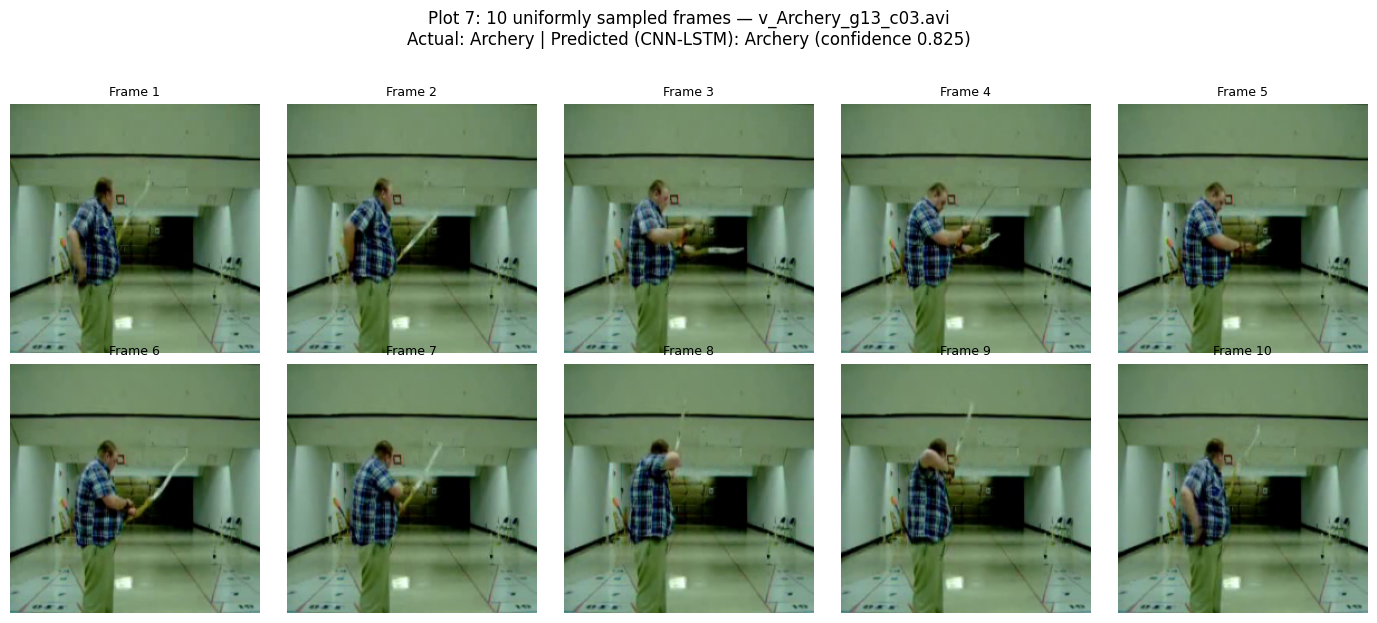

saved -> exp6_outputs/plot8_video_loss_accuracy.png


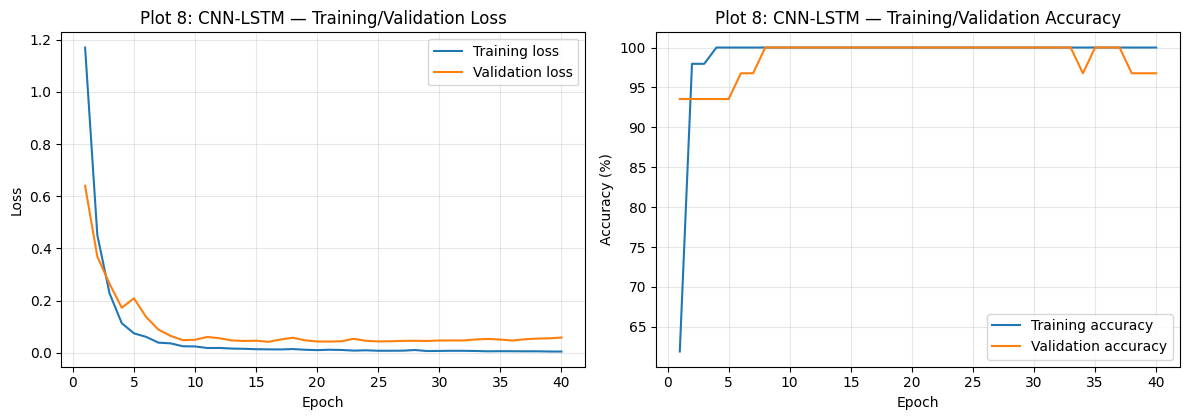

saved -> exp6_outputs/plot9_video_confusion_matrix.png


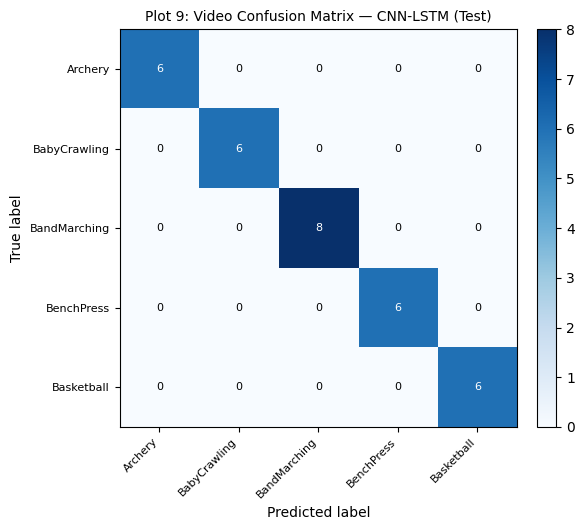

--- CNN-LSTM: per-class recall (%) and misclassification counts ---
       Class  Support  Correct  Errors  Recall %
     Archery        6        6       0     100.0
BabyCrawling        6        6       0     100.0
BandMarching        8        8       0     100.0
  BenchPress        6        6       0     100.0
  Basketball        6        6       0     100.0
Highest recall : Archery (100.00%)
Lowest recall  : Archery (100.00%)
Most errors    : Archery (0 misclassified windows)
Most frequent confusions (count, true -> predicted):

              precision    recall  f1-score   support

     Archery     1.0000    1.0000    1.0000         6
BabyCrawling     1.0000    1.0000    1.0000         6
BandMarching     1.0000    1.0000    1.0000         8
  BenchPress     1.0000    1.0000    1.0000         6
  Basketball     1.0000    1.0000    1.0000         6

    accuracy                         1.0000        32
   macro avg     1.0000    1.0000    1.0000        32
weighted avg     1.0000    1.

In [ ]:
Vb = V[best_video]

# ---- Predictions: predicted / actual / confidence (taken from the model's softmax output) ----
print("Video predictions (first 5 test videos):")
video_examples = []
for i in range(min(5, len(paths_te))):
    pc = int(Vb["pred"][i]); conf = float(Vb["prob"][i].max())
    video_examples.append(dict(video=os.path.basename(paths_te[i]), predicted=chosen[pc], actual=chosen[int(yv_te[i])], confidence=conf))
    print(f"  {os.path.basename(paths_te[i])}\n     Predicted class : {chosen[pc]}\n     Actual class    : {chosen[int(yv_te[i])]}\n     Confidence      : {conf:.4f}")
RESULTS["video_examples"] = video_examples
print(f"Mean max-softmax confidence on all test videos: {Vb['prob'].max(1).mean():.4f}")

# ---- Plot 7: sampled frames of one test video (already one combined 2x5 grid figure) ----
frames = read_frames(paths_te[0])
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i]); ax.axis("off"); ax.set_title(f"Frame {i+1}", fontsize=9)
plt.suptitle(f"Plot 7: {N_FRAMES} uniformly sampled frames — {os.path.basename(paths_te[0])}\n"
             f"Actual: {chosen[int(yv_te[0])]} | Predicted (CNN-{best_video}): {chosen[int(Vb['pred'][0])]} (confidence {Vb['prob'][0].max():.3f})", y=1.03)
plt.tight_layout(); save_fig("plot7_video_sample_frames.png"); plt.show()

# ---- Plot 8: loss + accuracy as ONE combined figure ----
plot_curves_combined(Vb["history"], f"CNN-{best_video}", "plot8_video_loss_accuracy.png", "Plot 8", "Plot 8")

# ---- Plot 9: confusion matrix ----
fig, ax = plt.subplots(figsize=(6.2, 5.4))
im = plot_confusion_ax(ax, Vb["cm"], chosen, f"Plot 9: Video Confusion Matrix — CNN-{best_video} (Test)")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout(); save_fig("plot9_video_confusion_matrix.png"); plt.show()
RESULTS["video_confusion_analysis"] = confusion_report(f"CNN-{best_video}", Vb["cm"], chosen)
print(classification_report(yv_te, Vb["pred"], target_names=chosen, digits=4, zero_division=0))

## 12. Sequence-to-sequence learning — synthetic reversal task

Encoder LSTM → context state $(h, c)$ → Decoder LSTM → Dense softmax.
Digits are `1…9`; token `0` is reserved as the decoder **START** symbol.
**Training uses teacher forcing** (the decoder is fed the ground-truth previous token). **Evaluation uses greedy decoding** (the decoder is fed its own previous prediction), which is the realistic setting.

Seq2seq data -> train / val / test sequences: 7000 1500 1500 | sequence length: 6 | vocabulary (incl. START): 10
Example pair: input [7, 4, 8, 5, 7, 3] -> target [3, 7, 5, 8, 4, 7] | decoder input [0, 3, 7, 5, 8, 4]


Model: "seq2seq_reversal"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ enc_in (InputLayer) │ (None, 6)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_in (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_embed           │ (None, 6, 16)     │        160 │ enc_in[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_embed           │ (None, None, 16)  │        160 │ dec_in[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 64),      │     20,736 │ enc_embed[0][0]   │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │     20,736 │ dec_embed[0][0],  │
│                     │ 64), (None, 64),  │            │ encoder_lstm[0][… │
│                     │ (None, 64)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_out (Dense)     │ (None, None, 10)  │        650 │ decoder_lstm[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 42,442 (165.79 KB)

 Trainable params: 42,442 (165.79 KB)

 Non-trainable params: 0 (0.00 B)

  epoch   1 | loss 2.0273 acc 0.2398 | val_loss 1.6341 val_acc 0.3714
  epoch   5 | loss 0.1804 acc 0.9820 | val_loss 0.1462 val_acc 0.9882
  epoch  10 | loss 0.0400 acc 0.9989 | val_loss 0.0455 val_acc 0.9961
  epoch  15 | loss 0.0175 acc 0.9997 | val_loss 0.0191 val_acc 0.9991
  epoch  20 | loss 0.0075 acc 1.0000 | val_loss 0.0098 val_acc 0.9997
  epoch  25 | loss 0.0044 acc 1.0000 | val_loss 0.0062 val_acc 0.9997
  epoch  30 | loss 0.0028 acc 1.0000 | val_loss 0.0043 val_acc 0.9997
Seq2seq training time: 34.10 s | trainable params: 42,442

Test token accuracy (greedy decoding)    : 99.99%
Test sequence accuracy (greedy decoding) : 99.93%
Teacher-forced test token accuracy / loss: 99.99% / 0.0035  (for reference only)
Final training loss: 0.0028 | final validation loss: 0.0043
Number of completely wrong sequences: 1 of 1500

First five test examples:
 Sample     Input Sequence   Predicted Output    Expected Output  Correct
      1 [2, 7, 2, 7, 3, 8] [8, 3, 7, 2, 7, 2] [8, 3, 7, 2, 7,

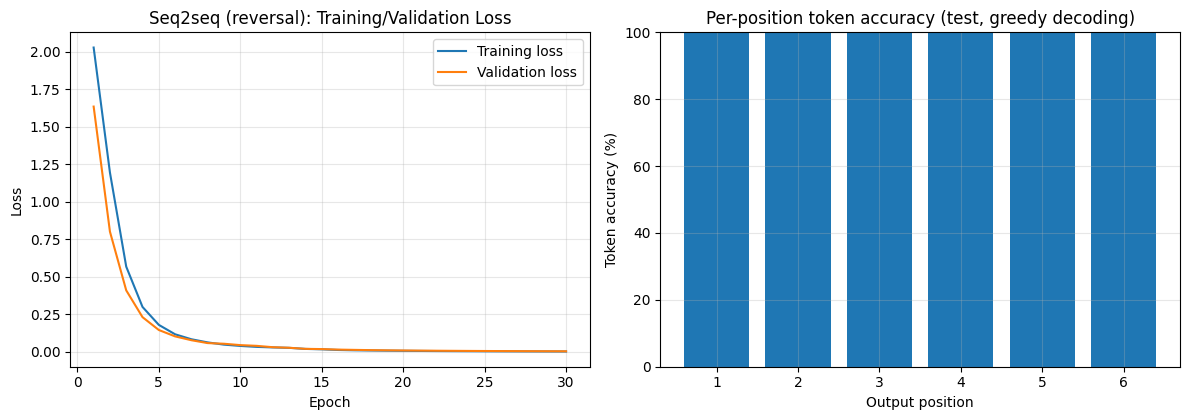

In [ ]:
S_VOCAB, S_LEN, S_N, S_HID, S_EMB = 10, 6, 10000, 64, 16
S_EPOCHS, S_BATCH = 30, 64

rs = np.random.RandomState(SEED)
Xs = rs.randint(1, S_VOCAB, size=(S_N, S_LEN))          # digits 1..9
Ys = Xs[:, ::-1].copy()                                  # reversed sequence
Ds = np.concatenate([np.zeros((S_N, 1), dtype=int), Ys[:, :-1]], axis=1)   # decoder input = START + shifted target

n_tr, n_va = int(0.70 * S_N), int(0.15 * S_N)
Xs_tr, Xs_va, Xs_te = Xs[:n_tr], Xs[n_tr:n_tr+n_va], Xs[n_tr+n_va:]
Ys_tr, Ys_va, Ys_te = Ys[:n_tr], Ys[n_tr:n_tr+n_va], Ys[n_tr+n_va:]
Ds_tr, Ds_va, Ds_te = Ds[:n_tr], Ds[n_tr:n_tr+n_va], Ds[n_tr+n_va:]
print("Seq2seq data -> train / val / test sequences:", len(Xs_tr), len(Xs_va), len(Xs_te), "| sequence length:", S_LEN, "| vocabulary (incl. START):", S_VOCAB)
print("Example pair: input", Xs[0].tolist(), "-> target", Ys[0].tolist(), "| decoder input", Ds[0].tolist())

set_seed()
enc_in = layers.Input((S_LEN,), dtype="int32", name="enc_in")
enc_emb = layers.Embedding(S_VOCAB, S_EMB, name="enc_embed")(enc_in)
_, enc_h, enc_c = layers.LSTM(S_HID, return_state=True, name="encoder_lstm")(enc_emb)

dec_in = layers.Input((None,), dtype="int32", name="dec_in")
dec_embed = layers.Embedding(S_VOCAB, S_EMB, name="dec_embed")
dec_lstm  = layers.LSTM(S_HID, return_sequences=True, return_state=True, name="decoder_lstm")
dec_dense = layers.Dense(S_VOCAB, activation="softmax", name="dec_out")
dseq, _, _ = dec_lstm(dec_embed(dec_in), initial_state=[enc_h, enc_c])
s2s = keras.Model([enc_in, dec_in], dec_dense(dseq), name="seq2seq_reversal")
s2s.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
s2s.summary()

t0 = time.time()
sh = s2s.fit([Xs_tr, Ds_tr], Ys_tr, validation_data=([Xs_va, Ds_va], Ys_va),
             epochs=S_EPOCHS, batch_size=S_BATCH, verbose=0, callbacks=[EveryN(5)])
s2s_time = time.time() - t0
print(f"Seq2seq training time: {s2s_time:.2f} s | trainable params: {n_trainable(s2s):,}")

# ---- inference models (share the trained layers) ----
enc_model = keras.Model(enc_in, [enc_h, enc_c])
h_in = layers.Input((S_HID,)); c_in = layers.Input((S_HID,)); tok_in = layers.Input((1,), dtype="int32")
o_, h_o, c_o = dec_lstm(dec_embed(tok_in), initial_state=[h_in, c_in])
dec_model = keras.Model([tok_in, h_in, c_in], [dec_dense(o_), h_o, c_o])

def greedy_decode(X):
    h_, c_ = enc_model.predict(X, verbose=0)
    tok = np.zeros((len(X), 1), dtype="int32"); outs = []
    for _ in range(S_LEN):
        p_, h_, c_ = dec_model.predict([tok, h_, c_], verbose=0)
        tok = p_[:, -1, :].argmax(-1).astype("int32")[:, None]
        outs.append(tok)
    return np.concatenate(outs, axis=1)

pred_s = greedy_decode(Xs_te)
token_acc = float((pred_s == Ys_te).mean() * 100)
seq_acc = float((pred_s == Ys_te).all(axis=1).mean() * 100)
tf_loss, tf_acc = s2s.evaluate([Xs_te, Ds_te], Ys_te, verbose=0)
print(f"\nTest token accuracy (greedy decoding)    : {token_acc:.2f}%")
print(f"Test sequence accuracy (greedy decoding) : {seq_acc:.2f}%")
print(f"Teacher-forced test token accuracy / loss: {tf_acc*100:.2f}% / {tf_loss:.4f}  (for reference only)")
print(f"Final training loss: {sh.history['loss'][-1]:.4f} | final validation loss: {sh.history['val_loss'][-1]:.4f}")
print(f"Number of completely wrong sequences: {(~(pred_s == Ys_te).all(axis=1)).sum()} of {len(Ys_te)}")

ex = pd.DataFrame({"Sample": range(1, 6), "Input Sequence": [Xs_te[i].tolist() for i in range(5)],
                   "Predicted Output": [pred_s[i].tolist() for i in range(5)],
                   "Expected Output": [Ys_te[i].tolist() for i in range(5)],
                   "Correct": [bool((pred_s[i] == Ys_te[i]).all()) for i in range(5)]})
print("\nFirst five test examples:"); print(ex.to_string(index=False))
wrong = np.where(~(pred_s == Ys_te).all(axis=1))[0][:5]
if len(wrong):
    print("\nFirst incorrect test examples (for error analysis):")
    for i in wrong:
        print(f"  input {Xs_te[i].tolist()} | predicted {pred_s[i].tolist()} | expected {Ys_te[i].tolist()}")

# per-position accuracy (which output positions fail?)
pos_acc = (pred_s == Ys_te).mean(axis=0) * 100
print("\nPer-position token accuracy (output position 1..%d):" % S_LEN, np.round(pos_acc, 2).tolist())

# ---- seq2seq loss + per-position accuracy as ONE combined figure ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ep = np.arange(1, S_EPOCHS + 1)
axes[0].plot(ep, sh.history["loss"], label="Training loss"); axes[0].plot(ep, sh.history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Seq2seq (reversal): Training/Validation Loss"); axes[0].legend()
axes[1].bar(np.arange(1, S_LEN + 1), pos_acc)
axes[1].set_xlabel("Output position"); axes[1].set_ylabel("Token accuracy (%)"); axes[1].set_ylim(0, 100)
axes[1].set_title("Per-position token accuracy (test, greedy decoding)")
plt.tight_layout(); save_fig("seq2seq_loss_and_position_accuracy.png"); plt.show()

RESULTS["seq2seq"] = dict(token_accuracy=token_acc, sequence_accuracy=seq_acc,
                          teacher_forced_test_token_accuracy=float(tf_acc * 100), teacher_forced_test_loss=float(tf_loss),
                          final_train_loss=float(sh.history["loss"][-1]), final_val_loss=float(sh.history["val_loss"][-1]),
                          min_val_loss=float(min(sh.history["val_loss"])), epochs=S_EPOCHS, train_time_s=s2s_time,
                          params=n_trainable(s2s), seq_len=S_LEN, vocab=S_VOCAB, n_sequences=S_N,
                          split=[len(Xs_tr), len(Xs_va), len(Xs_te)],
                          per_position_accuracy=pos_acc.tolist(),
                          examples=[dict(input=Xs_te[i].tolist(), predicted=pred_s[i].tolist(), expected=Ys_te[i].tolist(),
                                         correct=bool((pred_s[i] == Ys_te[i]).all())) for i in range(5)])

## 13. Consolidated results

In [ ]:
rows = []
for k in KINDS:
    rows.append([k, R[k]["acc"], R[k]["precision"], R[k]["recall"], R[k]["f1"], R[k]["params"], R[k]["train_time"]])
for k in ["LSTM", "GRU"]:
    rows.append([f"CNN-{k}" + (" (selected)" if k == best_video else ""), V[k]["acc"], V[k]["precision"], V[k]["recall"], V[k]["f1"], V[k]["params"], V[k]["time"]])
cons = pd.DataFrame(rows, columns=["Model", "Accuracy (%)", "Precision (%)", "Recall (%)", "F1 (%)", "Trainable params", "Train time (s)"])
print("Consolidated results (macro-averaged precision/recall/F1 on the test sets):")
print(cons.round(2).to_string(index=False))

s2s_tab = pd.DataFrame([[token_acc, seq_acc, sh.history["loss"][-1], sh.history["val_loss"][-1], n_trainable(s2s), s2s_time]],
                       columns=["Token acc (%)", "Sequence acc (%)", "Final train loss", "Final val loss", "Params", "Train time (s)"], index=["Seq2seq LSTM"])
print("\nSequence-to-sequence results:"); print(s2s_tab.round(4).to_string())

RESULTS["consolidated"] = cons.to_dict(orient="records")

def to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump(RESULTS, f, indent=2, default=to_py)
cons.to_csv(os.path.join(OUT_DIR, "consolidated_results.csv"), index=False)
print("\nSaved results.json and consolidated_results.csv")

# ---- check that every required (now combined) figure exists ----
expected = ["plot1_temporal_sensor_signals.png",
            "plot23_rnn_loss_accuracy.png", "plot23_lstm_loss_accuracy.png", "plot23_gru_loss_accuracy.png",
            "plot23_all_models_loss_accuracy_grid.png",
            "plot4_confusion_all_models.png",
            "plot5_model_performance_comparison.png", "plot6_sequence_length_vs_f1.png",
            "plot7_video_sample_frames.png", "plot8_video_loss_accuracy.png",
            "plot9_video_confusion_matrix.png", "seq2seq_loss_and_position_accuracy.png"]
missing = [e for e in expected if not os.path.exists(os.path.join(OUT_DIR, e))]
print(f"All {len(expected)} required combined figures present." if not missing else f"MISSING figures: {missing}")

# ---- zip and download ----
shutil.make_archive("exp6_outputs", "zip", OUT_DIR)
print("Created exp6_outputs.zip (%.1f MB)" % (os.path.getsize("exp6_outputs.zip") / 1e6))
try:
    from google.colab import files
    files.download("exp6_outputs.zip")
except Exception as e:
    print("Not running in Colab (or download blocked). Zip is at ./exp6_outputs.zip", e)

Consolidated results (macro-averaged precision/recall/F1 on the test sets):
              Model  Accuracy (%)  Precision (%)  Recall (%)  F1 (%)  Trainable params  Train time (s)
                RNN         77.33          77.53       77.33   76.93              1974           27.94
               LSTM         94.44          94.80       94.44   94.41              6006           24.49
                GRU         94.67          94.72       94.67   94.66              4758           25.71
CNN-LSTM (selected)        100.00         100.00      100.00  100.00            168229            7.47
            CNN-GRU         93.75          95.00       93.33   93.14            126309            7.73

Sequence-to-sequence results:
              Token acc (%)  Sequence acc (%)  Final train loss  Final val loss  Params  Train time (s)
Seq2seq LSTM        99.9889           99.9333            0.0028          0.0043   42442         34.0961

Saved results.json and consolidated_results.csv
All 12 required co

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### What to send back for the LaTeX report
1. `exp6_outputs.zip` (all combined PNGs + `results.json`) — or upload the PNGs individually.
2. The printed output of the cells (especially Sections 2, 6–13) — copy/paste or screenshot.
3. Tell me if any cell failed or if you changed any configuration value (e.g. `N_SUBSET`, video classes).